# Quality Control with SpotSweeper (Visium HD Segmented)

## Introduction

In this notebook, we transition from data ingestion to **Quality Control (QC)**. Having structured and saved our _segmented_ Visium HD dataset in the [previous notebook](./03-data_ingestion_VisiumHD_segmented.ipynb), each observation now represents an individual segmented cell within our selected Region of Interest (ROI). Our primary objective is to identify and exclude low-quality cells, compromised membranes, and contiguous tissue artifacts prior to downstream normalization, clustering, and spatial domain detection. 

For a detailed theoretical treatment of spatial quality control and the mathematical principles behind spatially-aware filtering, consult the original slide presentations produced by the [SIB](https://www.sib.swiss/) and their companion study notes:

- [03. Preprocessing & Data Structures](../assets/notes/03-preprocessing_data_structures.md)
- [04. Spatial Transcriptomics Quality Control (Sequencing-Based)](../assets/notes/04-spatial_transcriptomics_QC_sequencing-based.md)

As established there, standard single-cell workflows rely on global outlier thresholds, e.g., _3 Median Absolute Deviations (MAD)_ from the sample median. However, spatial tissues exhibit pronounced histological heterogeneity, such as distinct tissue layers with naturally low cell densities or quiet transcriptional profiles. Applying global thresholds treats these valid biological structures as technical failures. To resolve this dilemma, we will leverage the **`SpotSweeper`** framework to evaluate cells relative to their immediate physical neighbors, isolating focal anomalies while preserving real tissue morphology. 

> While we focus here on segmented cell polygons, the exact same QC principles and `SpotSweeper` workflows apply directly to binned Visium HD grids (e.g., 8-µm or 16-µm squares) or classic spot-based Visium arrays.

## Learning objectives

- Calculate library size, transcriptional diversity, and mitochondrial fractions using `scuttle`.
- Map QC metrics across physical coordinates and tissue architecture using `Voyager` and `ggspavis`.
- Apply local Z-score thresholding across spatial k-NN neighborhoods to detect focal cellular damage without penalizing low-density tissue layers.
- Delineate multi-cell contiguous defects (e.g., tissue folds, tears, reagent drying) via multiscale mitochondrial variance modeling in `SpotSweeper`.
- Clean the spatial object to produce an uncompromised foundation for downstream analysis.

## Environment setup & data import

### Loading libraries

In [1]:
suppressPackageStartupMessages(suppressWarnings({
  # Core spatial object & serialization
  library(SpatialFeatureExperiment) # Loads SpatialExperiment under the hood
  library(alabaster.sfe)

  # Quality Control Frameworks
  library(scuttle)
  library(SpotSweeper)

  # Visualization & Distribution Plotting
  library(scater) # for ggcells()
  library(ggplot2)
  library(patchwork)
  library(ggside) # for marginal histograms
  library(Voyager)
  library(ggspavis) # for plotObsQC() and plotVisium()
}))

### Restoring the segmented SFE dataset

We reload the segmented Visium HD dataset that we structured, cropped to our Region of Interest (ROI), and serialized at the end of the [previous notebook](./03-data_ingestion_VisiumHD_segmented.ipynb). 

Because we saved our object using the modular `alabaster.sfe` framework, we use the `readObject()` function to reconstruct the complete `SpatialFeatureExperiment` architecture from disk. This instantly restores our gene expression matrix, cell metadata, physical coordinates, and both underlying geometric layers (`cellSeg`, `nucSeg`) in a single step.

In [2]:
# Path to our saved Visium HD segmented dataset from the previous notebook
data_path <- "output/sfe_visiumhd_segmented"

# Reconstruct the SpatialFeatureExperiment object from the modular directory
sfe <- readObject(data_path)

# Verify the restored object dimensions, metadata, and colGeometries
sfe

>>> Reading SpatialExperiment

>>> Reading colgeometries



class: SpatialFeatureExperiment 
dim: 18132 34874 
metadata(1): Samples
assays(1): counts
rownames(18132): SAMD11 NOC2L ... MT-ND6 MT-CYB
rowData names(3): ID Symbol Type
colnames(34874): 80404 80411 ... 189341 189343
colData names(5): Sample Barcode sample_id cell_area_um2 nuc_area_um2
reducedDimNames(0):
mainExpName: NULL
altExpNames(0):
spatialCoords names(2) : pxl_col_in_fullres pxl_row_in_fullres
imgData names(4): sample_id image_id data scaleFactor

unit: micron
Geometries:
colGeometries: centroids (POINT), cellSeg (POLYGON), nucSeg (POLYGON) 

Graphs:
sample01: 

### Macro histological overview (H&E reference map)

Before computing molecular metrics, we inspect the underlying high-resolution Hematoxylin and Eosin (H&E) histology image stored in `imgData(sfe)`. By explicitly displaying calibrated coordinate rulers on the axes (in microns), this image serves as our macro anatomical reference map throughout the quality control workflow, allowing us to read physical coordinates directly when targeting specific tissue structures for high-resolution inspection.

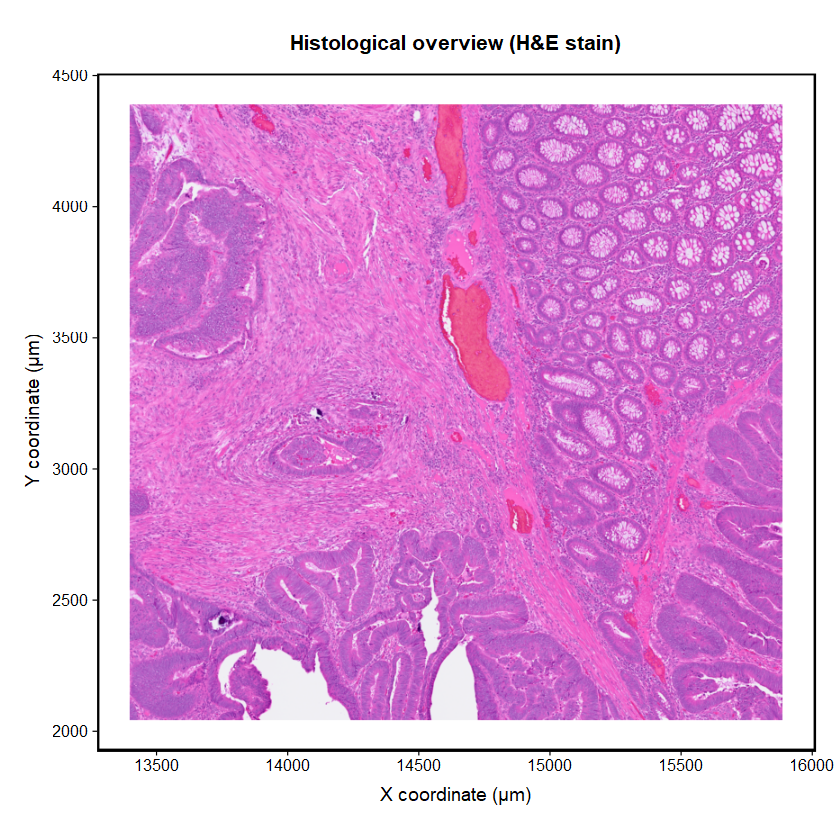

In [3]:
# Plot the full-slide H&E image with publication-quality formatting
plotImage(sfe, image_id = "hires") + 
  theme_linedraw(base_size = 11) + 
  theme(
    # Clean black frame around the histology image
    panel.border = element_rect(color = "black", fill = NA, linewidth = 0.8), 
    panel.grid   = element_blank(), 
    
    # Title formatting with proper vertical spacing
    plot.title   = element_text(face = "bold", size = 12, hjust = 0.5, margin = margin(b = 12)), 
    
    # Axis formatting
    axis.title.x = element_text(margin = margin(t = 8)), 
    axis.title.y = element_text(margin = margin(r = 8)), 
    axis.text    = element_text(color = "black", size = 9), 
    
    # Generous outer margins to prevent any clipping
    plot.margin  = margin(t = 15, r = 15, b = 15, l = 15)
  ) + 
  labs(
    title = "Histological overview (H&E stain)", 
    x = "X coordinate (µm)", 
    y = "Y coordinate (µm)")

This H&E stained section spans a ≈ 2,500 µm × 2,400 µm field of view illustrating the transition from normal colonic architecture to _invasive_, moderately differentiated colorectal adenocarcinoma. We can discriminate four major tissue compartments:

- **Normal colonic mucosa (upper right | X: 14,800–15,900 µm, Y: 2,800–4,400 µm):** Preserves intact, non-neoplastic colonic architecture with regularly spaced crypts of Lieberkühn seen in cross-section. The epithelium contains abundant pale, mucin-filled goblet cells supported by an orderly, immune-populated lamina propria.
- **Invasive colorectal adenocarcinoma (upper left & bottom | X: 13,400–14,200 µm, Y: 3,400–4,300 µm and X: 13,400–15,900 µm, Y: 2,050–2,800 µm):** Demonstrates malignant invasion through the muscularis mucosae with crowded, branching, and fused (cribriform) glands. Malignant cells display enlarged, hyperchromatic nuclei, marked loss of goblet cells, and dilated lumens filled with necrotic debris ("dirty necrosis").
- **Desmoplastic stroma and reactive submucosa (central band | X: 13,500–15,200 µm, Y: 2,600–4,300 µm):** A broad band of host tissue featuring dense, pink collagenous extracellular matrix and disrupted smooth muscle fibers induced by tumor invasion, interspersed with inflammatory mononuclear _immune infiltrate_ (predominantly lymphocytes).
- **Submucosal vasculature (upper center | X: 14,600–14,850 µm, Y: 3,300–4,400 µm):** Large, congested venules and arterioles packed with bright red/orange anucleate erythrocytes along the mucosal-stromal boundary. Lacking nucleated cells, these vascular lumens represent naturally transcript-sparse zones.

We can synthesize these spatial relationships and visualize how this section cuts across three-dimensional tissue architecture using a schematic block diagram. 

![3D schematic representation of colorectal adenocarcinoma tissue compartments](../assets/img/CRC_histology_3D_representation.png)

## Calculating per-cell QC metrics

To establish a baseline assessment of cellular integrity, we compute the standard trio of quality control metrics commonly evaluated in single-cell transcriptomics:

1. **Total Library Size (`sum`):** The total number of UMIs captured per segmented cell.
2. **Transcriptional Diversity (`detected`):** The number of unique genes with non-zero expression.
3. **Mitochondrial Fraction (`subsets_Mito_percent`):** The proportion of transcripts derived from the mitochondrial genome.

### Identifying mitochondrial genes

In intact, healthy cells, the plasma membrane retains cytoplasmic RNA. Conversely, cells subjected to mechanical stress, hypoxia, or membrane lysis leak cytoplasmic transcripts while retaining structurally resilient mitochondria, leading to an artificially elevated mitochondrial fraction. 

We begin by identifying all mitochondrially encoded genes, which follow the standard HGNC prefix `"MT-"`.

In [4]:
# Identify mitochondrial genes using the standard "MT-" prefix
is_mito <- rownames(sfe)[grepl("^MT-", rownames(sfe))]

# Inspect the identified mitochondrial gene symbols
is_mito

[1] "MT-ND1"  "MT-ND2"  "MT-CO1"  "MT-CO2"  "MT-ATP6" "MT-CO3"  "MT-ND3" 
 [8] "MT-ND4L" "MT-ND4"  "MT-ND5"  "MT-ND6"  "MT-CYB"

### Computing and inspecting per-cell metrics (scuttle)

We compute these baseline quality control metrics using `addPerCellQCMetrics()` from the **`scuttle`** package, the established standard across Bioconductor. This function simultaneously evaluates each segmented cell and appends three foundational columns to `colData`:

* **`sum` (Library Size):** Total Unique Molecular Identifiers (UMIs) captured per cell.
* **`detected` (Gene Diversity):** Number of unique genes with non-zero expression.
* **`subsets_Mito_percent` (Mitochondrial Fraction):** Percentage of reads mapping to mitochondrially encoded genes (`MT-`).

> For ultra-large datasets comprising millions of cells, the Bioconductor ecosystem is introducing the **`scrapper`** package (via `quickRnaQc()`), which leverages C++ optimizations to accelerate these calculations. However, `scuttle` remains the universal benchmark across the field.

In [5]:
# Compute per-cell QC metrics and append them directly to colData
sfe <- addPerCellQCMetrics(sfe, subsets = list(Mito = is_mito))

Warning message in addPerCellQCMetrics(sfe, subsets = list(Mito = is_mito)):
"'addPerCellQCMetrics' est obsolète.
Utilisez plutôt ‘scrapper::quickRnaQc.se’.
Voir help("Deprecated")"
Warning message in .per_cell_qc_metrics(assay(x, assay.type), subsets = subsets, :
"'perCellQCMetrics' est obsolète.
Utilisez plutôt ‘scrapper::computeRnaQcMetrics’.
Voir help("Deprecated")"
using unknown matrix fallback for 'CSC_H5SparseMatrixSeed'



We can inspect the updated `colData` table to confirm that these metrics were successfully appended.

In [6]:
# Inspect the newly calculated QC columns in colData
# Notice the square brackets [ , columns] AFTER colData(sfe)
colData(sfe)[, c("sum", "detected", "subsets_Mito_percent")] |> head()

DataFrame with 6 rows and 3 columns
            sum  detected subsets_Mito_percent
      <numeric> <numeric>            <numeric>
80404       789       668              5.57668
80411       340       312              6.17647
80412       362       331              2.20994
80429       726       597              9.09091
80439       790       657              5.44304
80443       712       598              8.98876

## Evaluating global outliers & fixed thresholds

### Bivariate distributions

In standard single-cell workflows, low-quality cells are typically filtered using fixed global cutoffs applied uniformly across the entire dataset. When adapting this approach to Visium HD, we must account for the platform's capture sensitivity. 

Unlike droplet-based scRNA-seq where individual cells often yield several thousand UMIs, Visium HD capture units exhibit significantly lower transcript counts. For example, in the community benchmark established in the [OSTA book](https://lmweber.org/OSTA/pages/seq-workflow-visium-hd-bin.html#dependencies), empirical thresholds for binned data remove 8-µm bins with fewer than 100 UMIs (scaled to 400 UMIs for 16-µm bins due to the 4-fold increase in surface area). 

For segmented cells, cell surface area varies organically rather than on a rigid grid, making fixed cutoffs even more sensitive. Before applying any hard filtering, we examine the joint distributions of our QC metrics. We generate scatter plots accompanied by 2D density contours and marginal histograms (via `ggside`), testing preliminary candidate cutoffs:

- **Library size (`sum`):** 300 UMIs
- **Transcript diversity (`detected`):** 200 unique genes
- **Mitochondrial proportion (`subsets_Mito_percent`):** 10%

In [7]:
# Initial candidate cutoffs (from Section 3, for visual comparison)
init_min_sum      <- 300
init_min_detected <- 200
init_max_mito     <- 10

In [8]:
# Plot 1: Library size vs. detected genes with marginal histograms
p1 <- ggcells(sfe, aes(x = detected, y = sum)) + 
  geom_point(alpha = 0.75, size = 1) +
  geom_density_2d(color = "blue") +
  scale_x_log10() +
  scale_y_log10() +
  geom_xsidehistogram(bins = 50, fill = "gray70", color = "white") + 
  geom_ysidehistogram(bins = 50, fill = "gray70", color = "white") + 
  geom_vline(xintercept = init_min_detected, color = "red", linetype = "dashed") +
  geom_hline(yintercept = init_min_sum, color = "red", linetype = "dashed") +
  labs(
    x = "Detected Genes (log10)", 
    y = "Total UMIs (log10)",
    title = "Library Size vs. Detected Genes"
  ) +
  theme_classic() +
  ggside::theme_ggside_void()

# Plot 2: Mitochondrial proportion vs. detected genes with marginal histograms
p2 <- ggcells(sfe, aes(x = detected, y = subsets_Mito_percent)) + 
  geom_point(alpha = 0.75, size = 1) +
  geom_density_2d(color = "blue") +
  scale_x_log10() +
  geom_xsidehistogram(bins = 50, fill = "gray70", color = "white") + 
  geom_ysidehistogram(bins = 50, fill = "gray70", color = "white") + 
  geom_vline(xintercept = init_min_detected, color = "red", linetype = "dashed") +
  geom_hline(yintercept = init_max_mito, color = "red", linetype = "dashed") +
  labs(
    x = "Detected Genes (log10)", 
    y = "Mitochondrial Fraction (%)",
    title = "Mitochondrial Fraction vs. Detected Genes"
  ) +
  theme_classic() +
  ggside::theme_ggside_void()

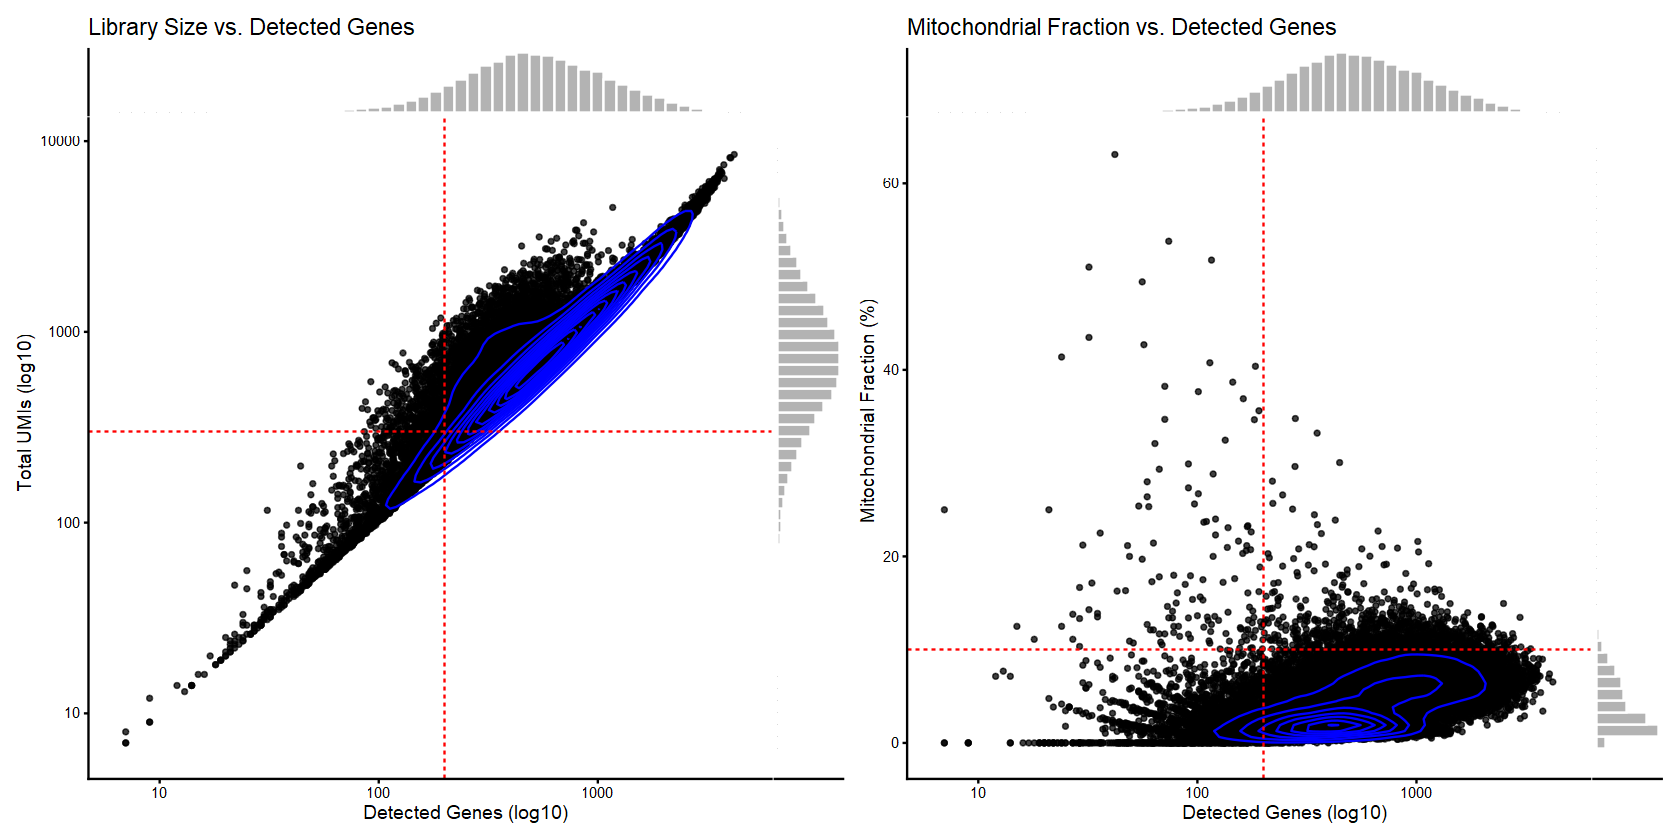

In [9]:
options(repr.plot.width = 14, repr.plot.height = 7)

# Combine panels side-by-side using patchwork
p1 + p2

#### Library size vs. detected genes

On the log-log scale, total UMIs and detected genes display strong linear concordance, reflecting consistent capture efficiency across the tissue. The bulk of segmented cells cluster between **300–1,500 detected genes** and **400–3,000 UMIs**, with a lower tail extending toward <50 UMIs and <30 genes. 

Our initial candidate cutoffs (**200 detected genes** and **300 UMIs**, red dashed lines) isolate this lower tail but graze the boundary of the main distribution. Setting global thresholds too high risks discarding biologically valid, low-yield populations (such as lymphocytes).

#### Mitochondrial fraction vs. detected genes

The majority of segmented cells cluster at baseline mitochondrial levels (**0%–5%**), indicating overall high tissue preservation. At the lower transcriptional extreme (<100–200 genes), a distinct subpopulation displays elevated mitochondrial fractions (>25%–30%). This inverse relationship reflects classic membrane compromise, where cytoplasmic transcripts are lost while heavier mitochondria remain trapped. 

Our candidate **10% cutoff** isolates these damaged cells, but also intersects transcriptionally active cells (>500 genes) with 10%–25% mitochondrial reads. For example, in metabolically active tissues like intestinal epithelium, moderate mitochondrial content often reflects physiological respiration rather than technical failure.

### Quantifying candidate global exclusions

Visualizing these bivariate distributions highlights the delicate trade-off between removing damaged debris and inadvertently discarding low-yield or metabolically specialized cell types. To measure the practical impact of these candidate cutoffs across our dataset, we record each threshold as a boolean flag in `colData` (`TRUE` = flagged for exclusion) and tabulate the resulting cell losses both individually and in combination.

In [10]:
# Flag cells failing each candidate global threshold (TRUE = flagged as low quality)
sfe$qc_lib_size  <- sfe$sum < init_min_sum
sfe$qc_detected  <- sfe$detected < init_min_detected
sfe$qc_mito_prop <- sfe$subsets_Mito_percent > init_max_mito

# Tabulate the number of cells flagged by each criterion
qc_cols <- grep("^qc", names(colData(sfe)))
sapply(colData(sfe)[qc_cols], table)

,qc_lib_size,qc_detected,qc_mito_prop
FALSE,30093,31265,33518
TRUE,4781,3609,1356


Applying these _naive global cutoffs_ would eliminate nearly 14% of the dataset, a substantial loss driven overwhelmingly by the library size filter (<300 UMIs). In standard scRNA-seq, where droplets lack physical coordinates, analysts have no direct way to determine whether such low-yield observations represent damaged cells or physiologically intact, quiescent lineages.

### Spatial diagnosis of continuous QC metrics

In spatial transcriptomics, tissue architecture provides direct biological context to resolve this ambiguity.

#### Macroscopic slide view

Before evaluating binary exclusion gates, we first map the continuous distributions of library size (`sum`) and mitochondrial fraction (`subsets_Mito_percent`) across the slide using `Voyager::plotSpatialFeature()`. This enables us to inspect the natural spatial variation of each metric and observe whether low transcriptional yields or elevated mitochondrial proportions align with recognizable anatomical structures.

Scale for fill is already present.
Adding another scale for fill, which will replace the existing scale.
Scale for fill is already present.
Adding another scale for fill, which will replace the existing scale.


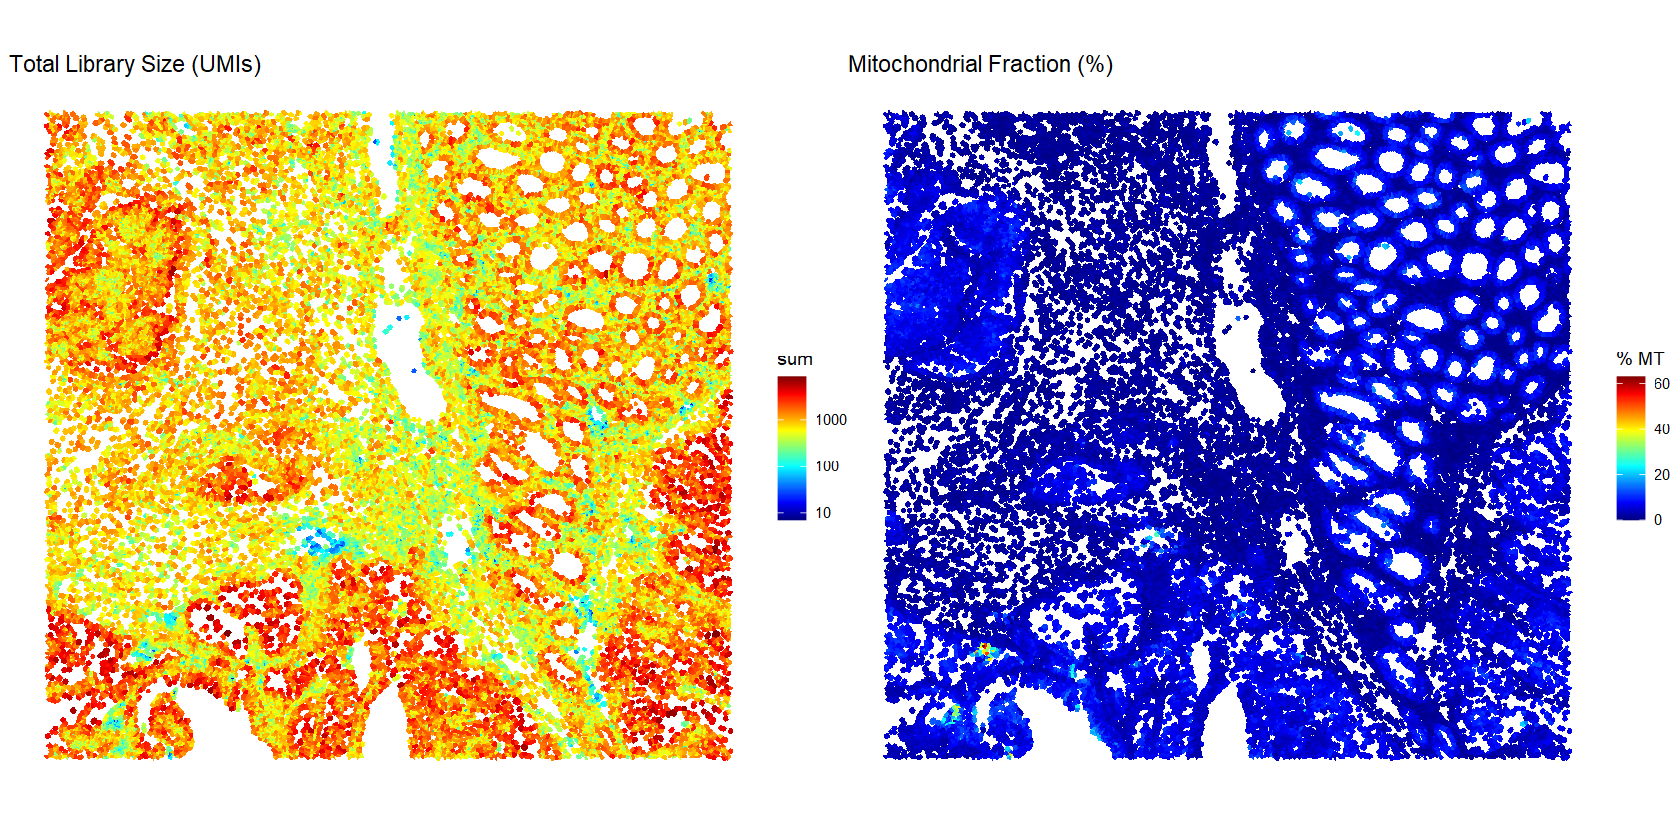

In [11]:
# Map total library size on log10 scale across full slide
p_spatial_lib  <- plotSpatialFeature(sfe, colGeometryName = "cellSeg", features = "sum") +
  scale_fill_gradientn(colors = pals::jet(), trans = "log10") +
  labs(title = "Total Library Size (UMIs)")

# Map mitochondrial fraction across full slide
p_spatial_mito  <- plotSpatialFeature(sfe, colGeometryName = "cellSeg", features = "subsets_Mito_percent") +
  scale_fill_gradientn(colors = pals::jet(), name = "% MT") +
  labs(title = "Mitochondrial Fraction (%)")

p_spatial_lib  + p_spatial_mito 

Across the full section, macroscopic QC distributions mirror the underlying histological architecture. Columnar epithelial cells forming the colonic crypts produce high transcriptional yields (bright red/orange rings; left plot), whereas the surrounding lamina propria and interstitial stroma yield lower baseline UMI counts (yellow/cyan). Concurrently, mitochondrial content remains at a healthy baseline across the vast majority of intact tissue (<5%, dark blue; right plot), punctuated by localized spikes along the lower tissue margin.

#### High-resolution zoom on the invasive front

To investigate whether low UMI counts reflect genuine technical lysis or legitimate cell-type biology, we select a high-interest region for close inspection. Rather than guessing arbitrary coordinates, we cross-reference our initial H&E histological overview (using its calibrated physical axes in microns) against these macroscopic QC maps. 

By reading the physical coordinate rulers directly off the axes, we define a 700 × 700 µm viewport (X ∈ [13750, 14450], Y ∈ [2400, 3100]). This window captures three contrasting histological microenvironments within a single field of view: intact transcriptionally dense neoplastic crypts, an inter-glandular stromal pocket exhibiting low UMI counts, and a segment of the damaged lower tissue margin.

In [12]:
# Define coordinates for the 700×700µm zoom region
zoom_xlim <- c(13750, 14450)
zoom_ylim <- c(2400, 3100)

We first project this target bounding box onto the full-slide H&E stain alongside its high-resolution histological zoom to confirm anatomical localization, before evaluating both QC metrics at cellular resolution with `coord_sf()`. 

> Unlike subsetting the underlying dataset in R memory, `coord_sf(xlim, ylim)` dynamically adjusts the visual viewport on the `ggplot` canvas using physical micron coordinates, strictly preserving the 1:1 spatial aspect ratio so cell geometries remain undistorted.

In [13]:
# Define the high-resolution viewport using physical micron bounds
zoom_hotspot <- coord_sf(
  xlim = zoom_xlim, 
  ylim = zoom_ylim)

In [14]:
# Shared publication-ready theme for histology plots
theme_he <- theme_linedraw(base_size = 11) + 
  theme(
    panel.border = element_rect(color = "black", fill = NA, linewidth = 0.8), 
    panel.grid   = element_blank(), 
    plot.title   = element_text(face = "bold", size = 11, hjust = 0.5, margin = margin(b = 10)), 
    axis.text    = element_text(color = "black", size = 9), 
    plot.margin  = margin(t = 10, r = 10, b = 10, l = 10)
  )

In [15]:
# 1. Macro H&E with the target ROI bounding box
p_he_macro <- plotImage(sfe, image_id = "hires") + 
  annotate(
    "rect", 
    xmin = zoom_xlim[1], xmax = zoom_xlim[2], 
    ymin = zoom_ylim[1], ymax = zoom_ylim[2], 
    color = "firebrick", fill = NA, linewidth = 1.1
  ) + 
  labs(
    title = "Macro H&E overview (red box = target zoom region)", 
    x = "X coordinate (µm)", 
    y = "Y coordinate (µm)"
  ) + 
  theme_he

# 2. High-resolution zoom directly into the H&E histology
p_he_zoom <- plotImage(sfe, image_id = "hires") + 
  zoom_hotspot + 
  labs(
    title = "Zoomed H&E Region (700 × 700 µm)", 
    x = "X coordinate (µm)", 
    y = "Y coordinate (µm)"
  ) + 
  theme_he

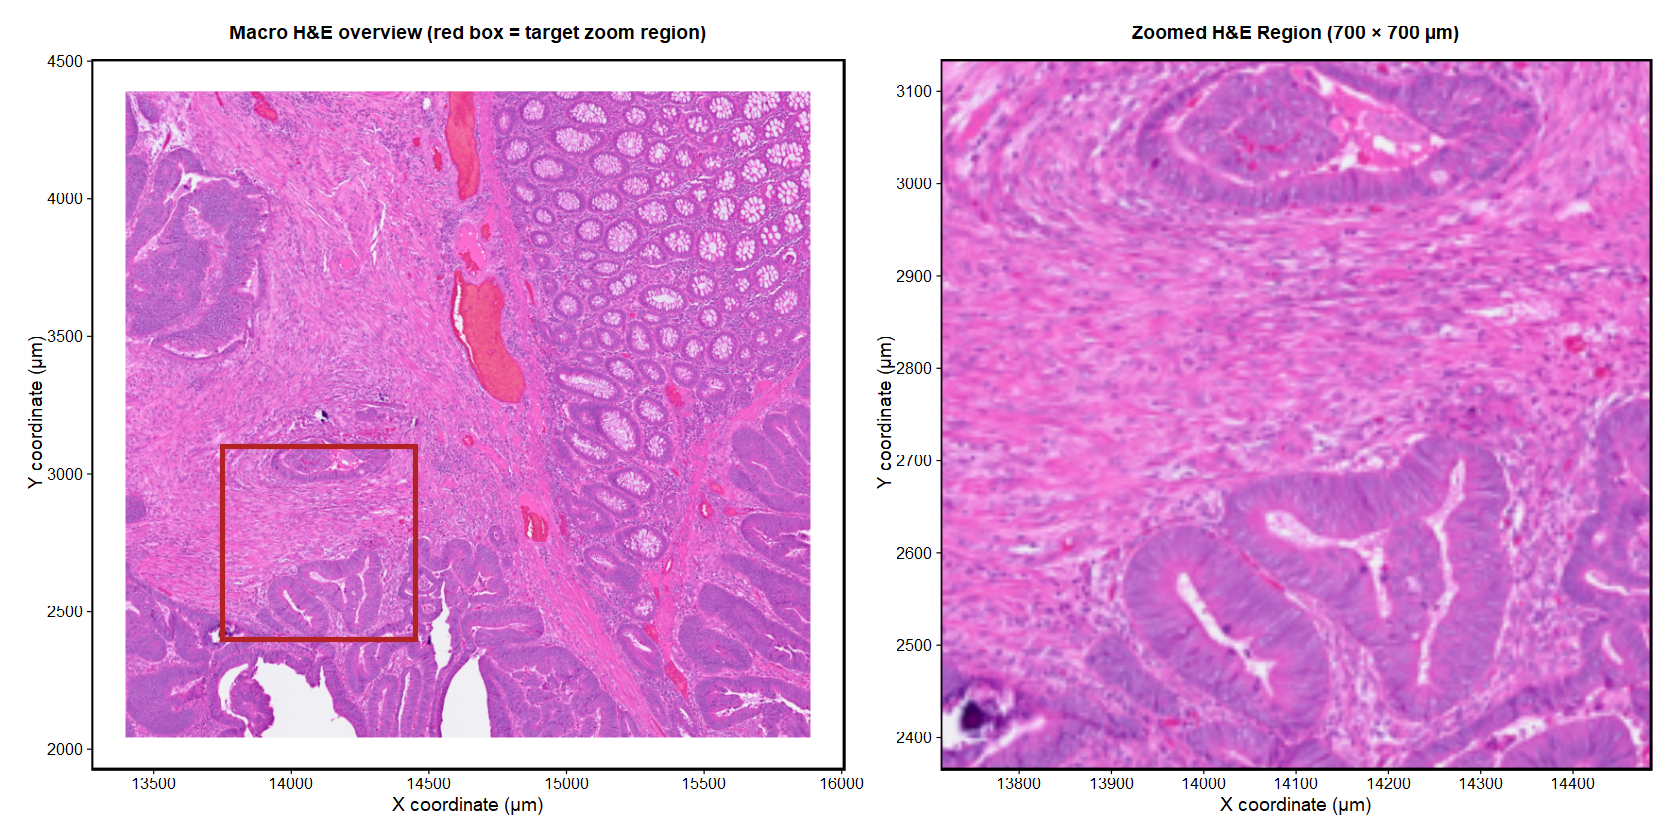

In [16]:
# Display both H&E views side-by-side
p_he_macro + p_he_zoom

This high-resolution viewport (X: 13,750–14,450 µm, Y: 2,400–3,100 µm) resolves three distinct micro-anatomical structures along the tumor-stroma interface:

1. Along the lower quadrant (Y: 2,400–2,750 µm) and at an isolated upper gland (X ≈ 14,150 µm, Y ≈ 3,020 µm), crowded, hyperchromatic malignant epithelium forms the invasive tumor front. Their high cellular packing density and metabolic activity predict robust baseline mRNA capture.
2. Traversing the center (Y: 2,700–2,950 µm) is a reactive desmoplastic stroma of dense collagen fibers and spindle-shaped fibroblasts. Due to their small cytoplasmic volume within an extensive extracellular matrix, their transcriptional yield is naturally modest, reflecting histology rather than technical failure.
3. At the lower-left edge (X ≈ 13,750 µm, Y ≈ 2,420 µm), the tissue ends against empty slide space with a dark clump of crushed debris. This cryosectioning tear represents genuine mechanical damage and membrane rupture.

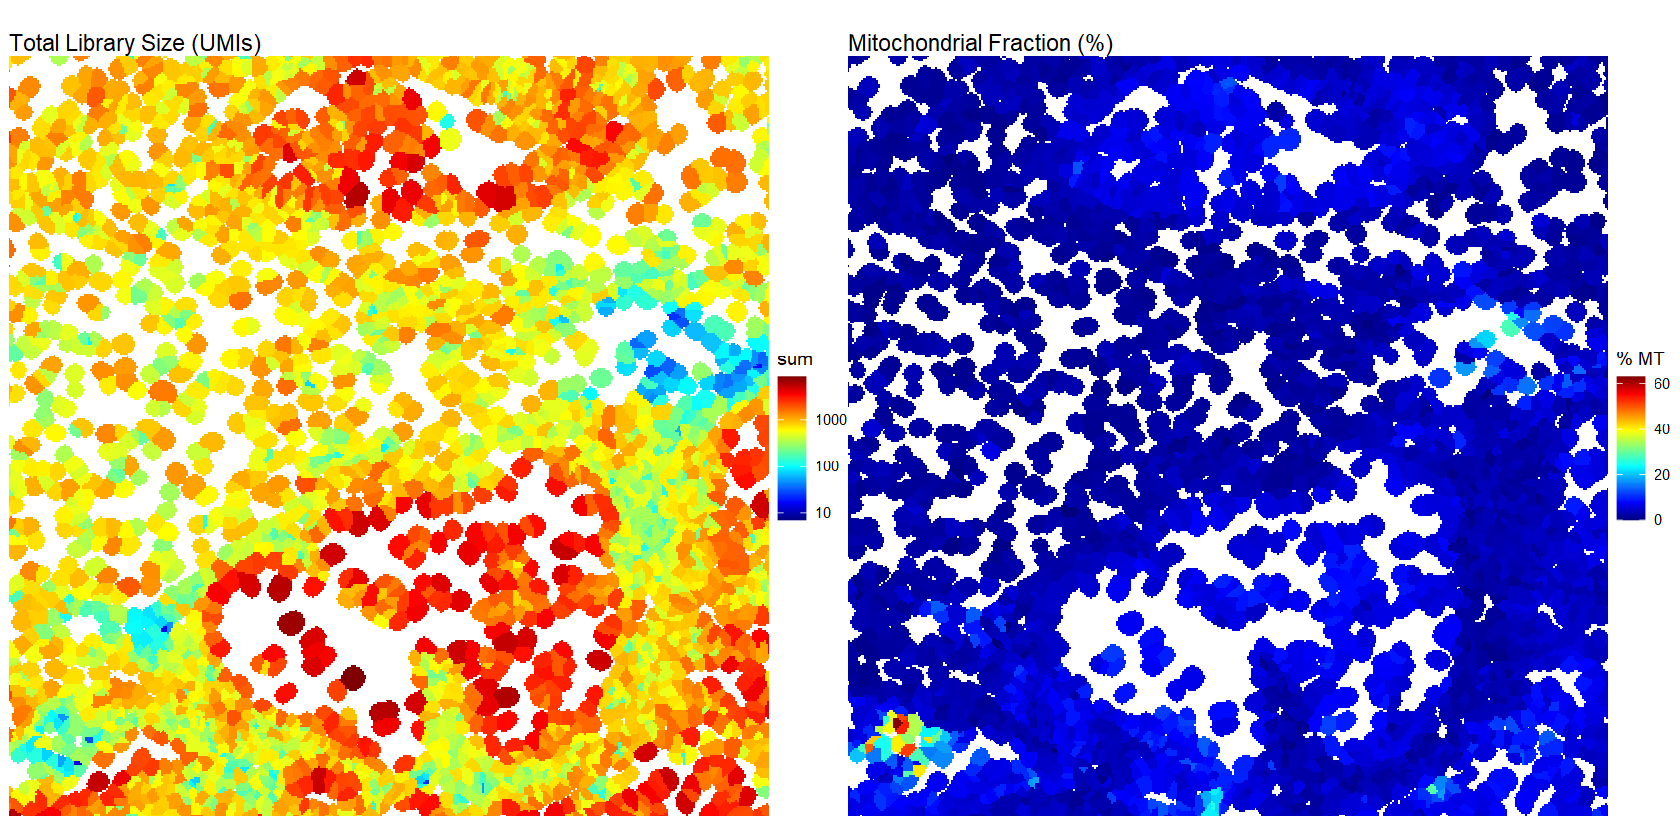

In [17]:
# Render the zoomed QC metrics side-by-side using the exact same viewport
(p_spatial_lib + zoom_hotspot) + (p_spatial_mito + zoom_hotspot)

Along the lower-left margin, the cluster coinciding with our histological cryosectioning tear displays elevated mitochondrial fractions (30%–60%, yellow/red) directly coupled with depressed UMI counts (<100, cyan). This co-occurrence represents the textbook hallmark of **plasma membrane compromise**, where cytoplasmic mRNA diffused away while resilient mitochondria were trapped inside. This is an authentic technical defect that warrants exclusion. 

Conversely, across the central desmoplastic stroma (and the upper-right pocket between crypts), cells exhibit similarly modest UMI yields (<200–300, cyan/yellow). Crucially, their mitochondrial fraction remains strictly at baseline (0%–5%, dark blue). These stromal cells are structurally intact; their lower library size reflects **small cytoplasmic volume and normal histology** (spindle fibroblasts embedded in collagen matrix), not technical failure. 

A rigid global cutoff (`sum < 300`) treats both of these regions identically, indiscriminately discarding healthy stromal cells alongside damaged debris. To evaluate how severely global thresholds penalize these biological compartments, we next map our boolean candidate exclusion flags across the tissue.

### Spatial diagnosis of candidate exclusions

We now project our boolean exclusion flags (`qc_lib_size` and `qc_mito_prop`) onto the tissue coordinates to evaluate *which* histological structures would be eliminated by these candidate cutoffs. We render these flags across the full slide, and apply our `zoom_hotspot` viewport to observe the cellular boundaries up close.

#### Macroscopic slide view

Scale for fill is already present.
Adding another scale for fill, which will replace the existing scale.
Scale for fill is already present.
Adding another scale for fill, which will replace the existing scale.


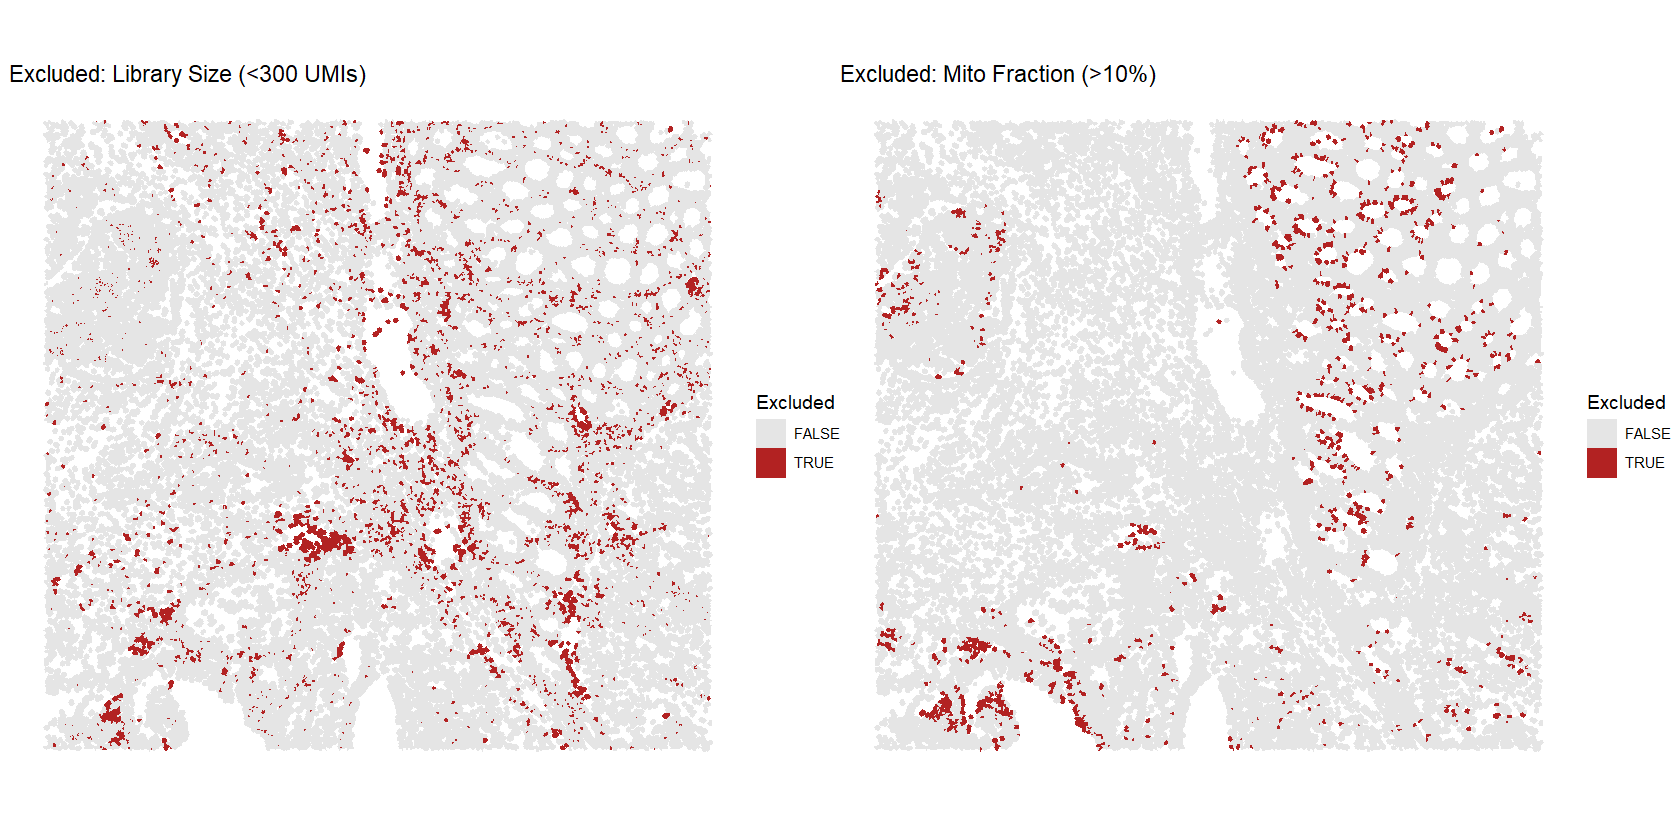

In [18]:
# Full-slide exclusions by Library Size (<300 UMIs)
p_excl_lib <- plotSpatialFeature(sfe, colGeometryName = "cellSeg", features = "qc_lib_size") +
  scale_fill_manual(values = c("FALSE" = "gray90", "TRUE" = "firebrick"), name = "Excluded") +
  labs(title = "Excluded: Library Size (<300 UMIs)")

# Full-slide exclusions by Mitochondrial Fraction (>10%)
p_excl_mito <- plotSpatialFeature(sfe, colGeometryName = "cellSeg", features = "qc_mito_prop") +
  scale_fill_manual(values = c("FALSE" = "gray90", "TRUE" = "firebrick"), name = "Excluded") +
  labs(title = "Excluded: Mito Fraction (>10%)")

# Display the full-slide exclusions side-by-side
p_excl_lib + p_excl_mito

Evaluating candidate exclusions across the entire tissue section demonstrates that neither metric behaves as random technical noise. Cells flagged by our library size cutoff (`qc_lib_size < 300 UMIs`) do not scatter randomly across the tissue. Instead, they assemble into extensive, continuous networks tracing the lamina propria in the normal mucosa and the central desmoplastic stroma. 

In parallel, mitochondrial exclusions (`qc_mito_prop > 10%`) display two distinct spatial patterns. Along the lower tissue boundary, excluded cells form dense, jagged clusters directly coinciding with physical tears from tissue sectioning. Throughout the intact tissue, however (particularly across the normal colonic mucosa on the right) elevated mitochondrial proportions assemble into repetitive, structured rings outlining crypts of Lieberkühn.

#### High-resolution zoom view

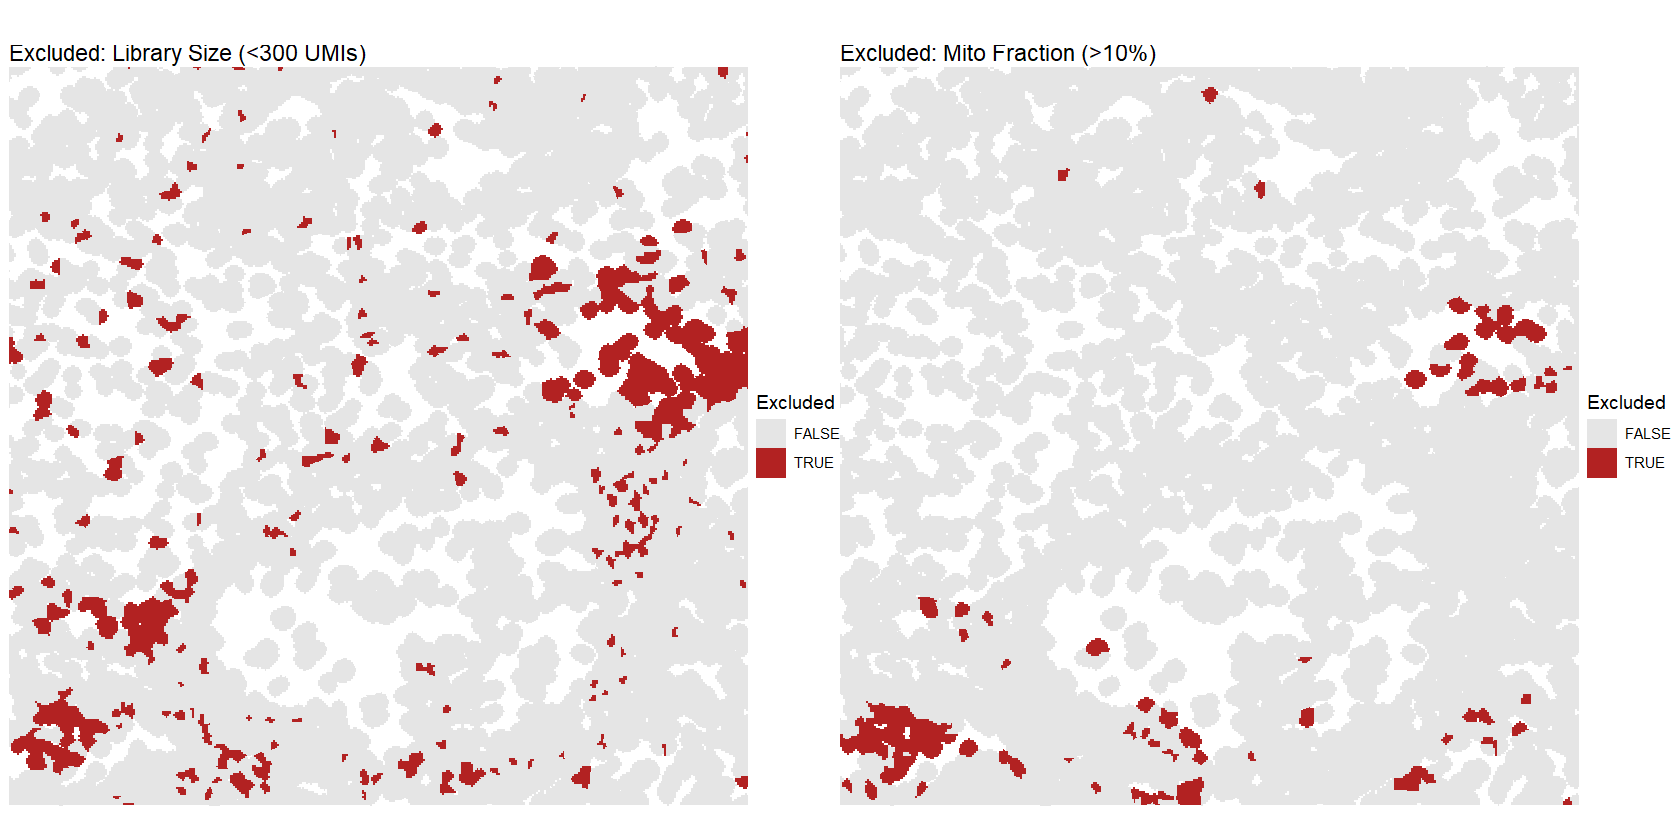

In [19]:
# Inspect the exclusions within our high-resolution zoom window
(p_excl_lib + zoom_hotspot) + (p_excl_mito + zoom_hotspot)

In the upper-right quadrant, the library size cutoff purges a dense, contiguous cluster of cells. Crucially, our mitochondrial filter spares this population, where values remain within baseline physiological levels (<10%, and predominantly <5%). These cells are viable and structurally intact; their modest RNA yield reflects biological morphology, specifically the small cytoplasmic volume and low basal transcription of reactive fibroblasts embedded in the desmoplastic stroma, rather than compromised integrity. 

Conversely, along the torn lower-left boundary, cells are flagged concurrently by both criteria: depressed UMI counts coupled with elevated mitochondrial fractions (>10%, reaching 30%–60%). This co-occurrence represents the textbook hallmark of mechanical lysis from cryosectioning, where cytoplasmic mRNA leaked through ruptured membranes while heavier mitochondria were retained.

## Local outlier detection with `SpotSweeper`

Global thresholds suffer from an inherent flaw: by ignoring spatial context, they treat physiologically low-yield stroma as technical failures. To remove damaged cells without discarding intact biological compartments, we must evaluate quality metrics relative to each cell's **immediate physical neighborhood**.

### Local outlier detection framework

The `SpotSweeper` package accomplishes this by constructing a spatial $k$-nearest neighbor (k-NN) graph based on physical $(x, y)$ coordinates. Through `SpotSweeper::localOutliers()`, each cell is evaluated against its local median ($m_i$) and local median absolute deviation ($\text{MAD}_i$):

$$\text{MAD}_i = \text{median}_{j \in \mathcal{N}_i}\left(|x_j - m_i|\right), \qquad z_i = 0.6745 \times \frac{x_i - m_i}{\text{MAD}_i}$$

Observations with a standardized local score of $|z_i| > 3$ are flagged as local outliers:

- A stromal cell yielding 200 UMIs surrounded by neighboring stromal cells that also yield ~200 UMIs receives a low local $Z$-score and is **retained**.
- An isolated cell yielding 200 UMIs surrounded by intact tumor epithelium yielding >1,500 UMIs, or an isolated cell displaying an aberrant mitochondrial spike relative to its neighbors, receives a high local $Z$-score and is **flagged for exclusion**.

### Quantifying local outliers

We now execute `SpotSweeper::localOutliers()` sequentially across our three QC metrics. For each metric, `SpotSweeper` evaluates each cell relative to its microenvironment and appends a boolean exclusion flag (`<metric>_outliers`) and its standardized local score (`<metric>_z`) directly to `colData(sfe)`. 

We tailor the search direction to the specific failure mode of each metric: testing for localized transcriptional dropouts (`direction = "lower"`) in library size (`sum`) and unique genes (`detected`), while testing for localized spikes (`direction = "higher"`) in mitochondrial fraction (`subsets_Mito_percent`). 

> Because sequencing counts follow log-normal distributions, setting `log = TRUE` for `sum` and `detected` stabilizes local variance across dynamic ranges. Percentages are already bounded on an arithmetic scale, so we maintain `log = FALSE`. By default, `localOutliers()` evaluates a spatial neighborhood of $k = 36$ nearest physical neighbors.

In [ ]:
# Flag localized dropouts in library size (unusually low UMIs relative to neighbors)
sfe <- localOutliers(
  sfe, 
  metric    = "sum", 
  direction = "lower", 
  log       = TRUE)

# Flag localized dropouts in detected genes (unusually low gene diversity)
sfe <- localOutliers(
  sfe, 
  metric    = "detected", 
  direction = "lower", 
  log       = TRUE)

# Flag localized spikes in mitochondrial percentage (unusually high % MT)
sfe <- localOutliers(
  sfe, 
  metric    = "subsets_Mito_percent", 
  direction = "higher", 
  log       = FALSE)

Warning message in BiocParallel::MulticoreParam(workers = workers):
"MulticoreParam() not supported on Windows, use SnowParam()"
Warning message in BiocParallel::MulticoreParam(workers = workers):
"MulticoreParam() not supported on Windows, use SnowParam()"
Warning message in BiocParallel::MulticoreParam(workers = workers):
"MulticoreParam() not supported on Windows, use SnowParam()"


A cell is deemed of low quality if it fails **any** of our individual local QC criteria. We therefore combine the three metric-specific flags using a logical OR (`|`) into a single composite boolean column, `sfe$local_outliers`.

In [21]:
# Construct a composite boolean flag (TRUE if flagged by ANY of the three metrics)
sfe$local_outliers <- as.logical(sfe$sum_outliers) |
  as.logical(sfe$detected_outliers) |
  as.logical(sfe$subsets_Mito_percent_outliers)

To assess the impact of spatially-aware filtering and determine how each metric contributes to the overall exclusion rate, we tabulate the flagged cell counts and their corresponding percentages across the dataset.

In [22]:
# Summarize individual and composite local outlier counts
data.frame(
  Metric = c(
    "Low Library Size (sum)", 
    "Low Gene Diversity (detected)", 
    "High Mitochondrial (% MT)", 
    "Combined Local Outliers"
  ),
  Flagged_Cells = c(
    sum(sfe$sum_outliers, na.rm = TRUE),
    sum(sfe$detected_outliers, na.rm = TRUE),
    sum(sfe$subsets_Mito_percent_outliers, na.rm = TRUE),
    sum(sfe$local_outliers, na.rm = TRUE)
  ),
  Percent_Dataset = round(c(
    mean(sfe$sum_outliers, na.rm = TRUE),
    mean(sfe$detected_outliers, na.rm = TRUE),
    mean(sfe$subsets_Mito_percent_outliers, na.rm = TRUE),
    mean(sfe$local_outliers, na.rm = TRUE)
  ) * 100, 2)
)

Metric,Flagged_Cells,Percent_Dataset
<chr>,<int>,<dbl>
Low Library Size (sum),58,0.17
Low Gene Diversity (detected),72,0.21
High Mitochondrial (% MT),206,0.59
Combined Local Outliers,298,0.85


Across the entire section, `SpotSweeper` flags only **298 cells (0.85%)** as combined local outliers. The vast majority of these localized anomalies stem from aberrant mitochondrial spikes (206 cells, 0.59%), whereas transcriptomic dropouts are exceedingly rare (58 cells for library size and 72 cells for gene diversity). 

While rigid global cutoffs threatened to eliminate nearly 14% of the dataset, spatially-aware filtering demonstrates that most low-count cells are viable histological components sharing similar transcript levels with their physical neighbors.

### Spatial distribution of local outliers

To verify where these 298 flagged cells reside anatomically, we map the composite `local_outliers` flag across the full section and within our high-resolution zoom window.

Scale for fill is already present.
Adding another scale for fill, which will replace the existing scale.


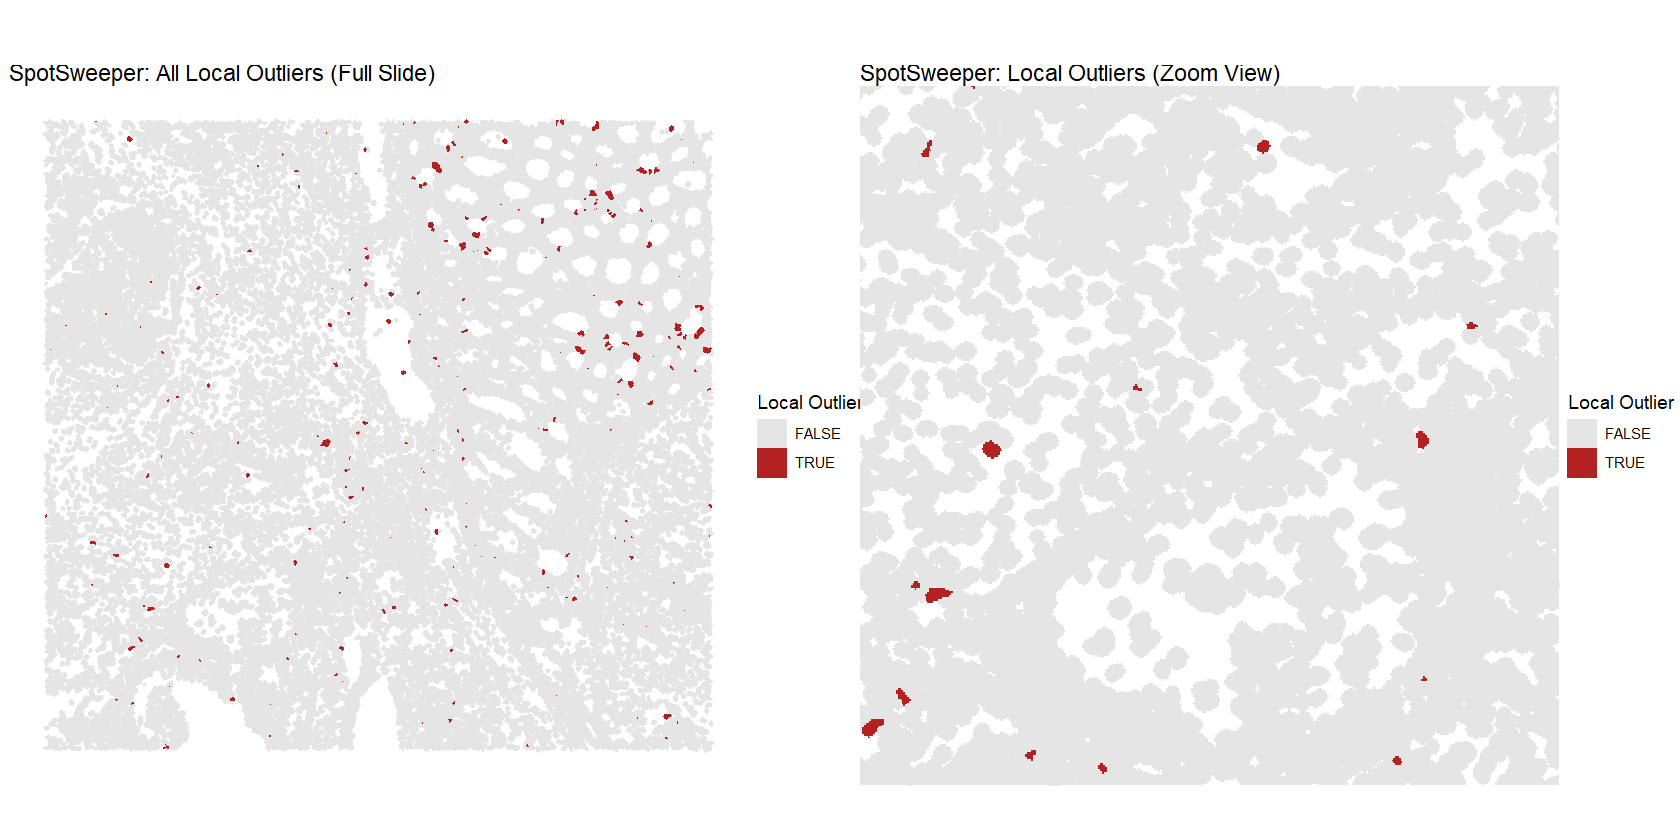

In [23]:
# Macroscopic slide view of all local outliers
p_local_macro <- plotSpatialFeature(sfe, colGeometryName = "cellSeg", features = "local_outliers") +
  scale_fill_manual(values = c("FALSE" = "gray90", "TRUE" = "firebrick"), name = "Local Outlier") +
  labs(title = "SpotSweeper: All Local Outliers (Full Slide)")

# High-resolution zoom at the invasive front
p_local_zoom <- p_local_macro + zoom_hotspot + labs(title = "SpotSweeper: Local Outliers (Zoom View)")

# Display side-by-side (macro and zoom)
p_local_macro + p_local_zoom

Rather than eliminating entire tissue compartments, local outliers manifest as isolated, focal events scattered across the slide. In regions where global cutoffs indiscriminately purged whole cell populations, such as the desmoplastic stroma in the upper-right of our zoom window, `SpotSweeper` recognizes that these cells do not differ from their immediate spatial neighbors, successfully preserving these intact stromal layers. The few flagged cells represent genuine focal dropouts or damaged cells bordering the lower-left cutting tear whose metrics deviate sharply from their microenvironment.

### Evaluating local Z-scores

Comparing the distribution of local Z-scores (`subsets_Mito_percent_z`) against our initial global cutoff (`qc_mito_prop > 10%`) illustrates how spatial context recalibrates outlier detection.

Scale for fill is already present.
Adding another scale for fill, which will replace the existing scale.


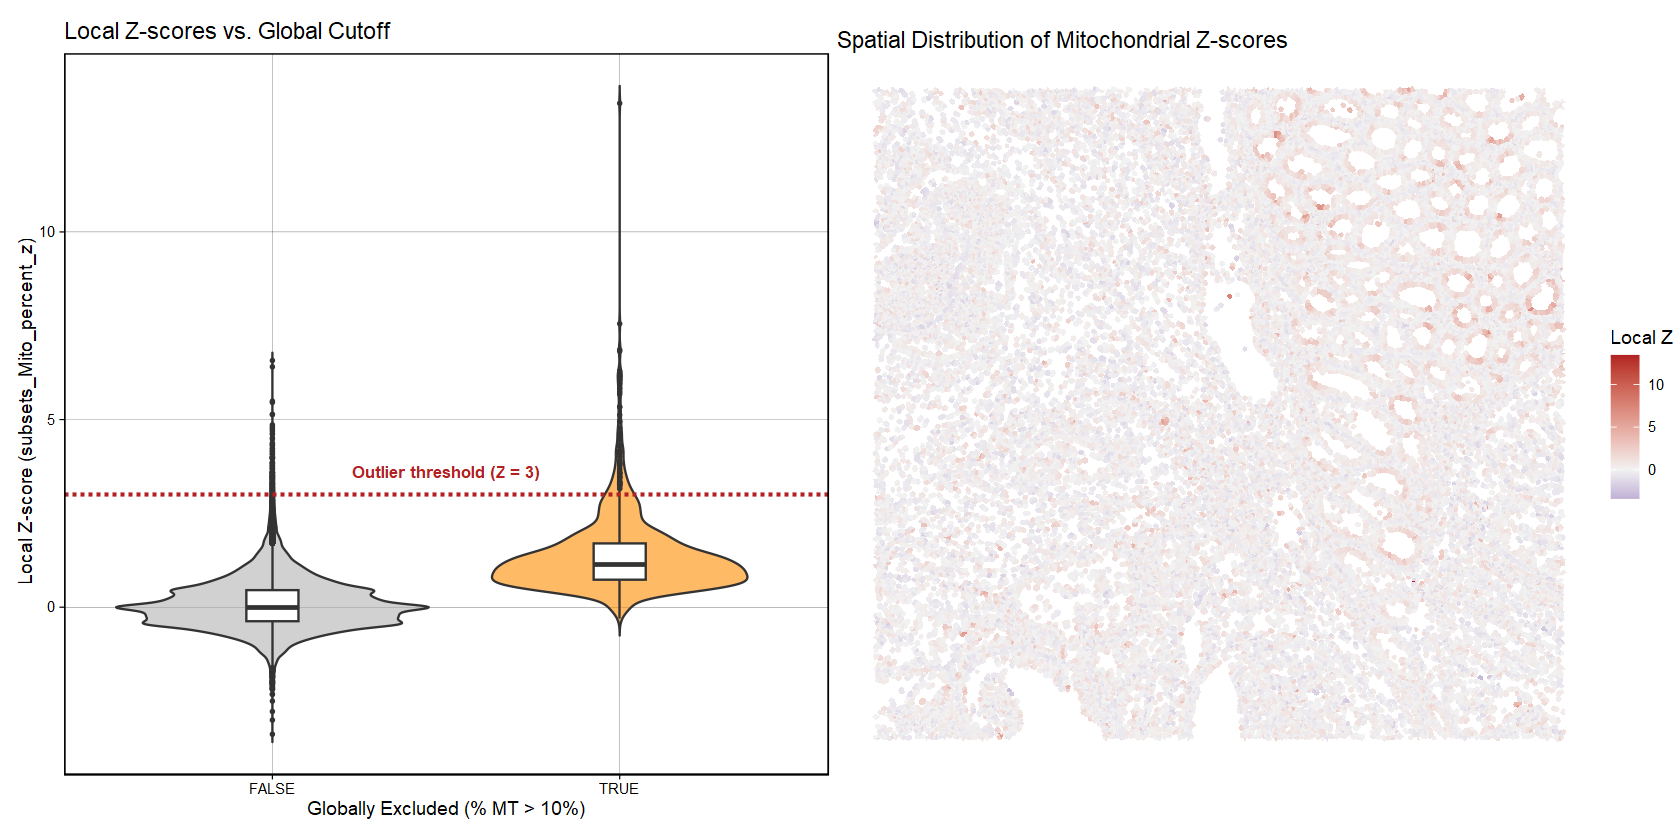

In [24]:
# Statistical distribution: Local Z-score by global status
p_violin <- ggplot(
  as.data.frame(colData(sfe)), 
  aes(x = qc_mito_prop, y = subsets_Mito_percent_z, fill = qc_mito_prop)
) +
  geom_violin(trim = FALSE, alpha = 0.6, show.legend = FALSE) +
  geom_boxplot(
    width = 0.15, fill = "white", outlier.size = 0.5, show.legend = FALSE) +
  geom_hline(
    yintercept = 3, linetype = "dashed", color = "firebrick", linewidth = 0.9) +
  annotate(
    "text", x = 1.5, y = 3.6, label = "Outlier threshold (Z = 3)", 
    color = "firebrick", fontface = "bold", size = 3.5) +
  scale_fill_manual(values = c("FALSE" = "gray70", "TRUE" = "darkorange")) +
  theme_linedraw(base_size = 11) +
  theme(panel.grid.minor = element_blank()) +
  labs(
    title = "Local Z-scores vs. Global Cutoff",
    x = "Globally Excluded (% MT > 10%)",
    y = "Local Z-score (subsets_Mito_percent_z)"
  )

# Spatial distribution of continuous local Z-scores
p_z_spatial <- plotSpatialFeature(
  sfe, colGeometryName = "cellSeg", features = "subsets_Mito_percent_z"
) +
  scale_fill_gradient2(
    low = "navy", mid = "gray95", high = "firebrick", midpoint = 0, name = "Local Z") +
  labs(title = "Spatial Distribution of Mitochondrial Z-scores")

# Display side-by-side
p_violin + p_z_spatial

The vast majority of cells with >10% mitochondrial content (orange violin) exhibit local Z-scores well below the outlier cutoff (median Z≈1.14). However, the continuous spatial map reveals an intriguing phenomenon: mildly elevated Z-scores (pink contours) systematically trace the crypts across the normal colonic mucosa. 

This reflects a classical **2D spatial boundary effect**. In a planar transverse section, crypts form thin 1-to-2 cell-wide epithelial rings surrounding an empty lumen. Because the Euclidean k-NN search (k=36) cannot find neighbors within the empty central void, it reaches outward into the adjacent lamina propria. The near-zero mitochondrial yield of this surrounding stroma (0%–3% MT) depresses the local neighborhood median, mathematically inflating the Z-scores of intact epithelial cells along the boundary! 

Crucially, because this is an interface artifact rather than true cellular lysis, the vast majority of these mucosal crypt cells remain below the strict filtering gate (Z≤3) and are spared (as confirmed in our previous macroscopic plot of all local outliers). Extreme scores (Z>3) are primarily restricted to the physically torn lower tissue margin, where mechanical sectioning caused genuine membrane rupture. 

Conversely, `SpotSweeper` identifies 124 cells whose mitochondrial content sits below the global 10% cutoff, but which represent genuine localized anomalies (Z>3) relative to their quiescent immediate neighbors.

## Two-tiered quality control

### Combining global floors with local context

Local outlier detection evaluates whether a cell's metrics deviate significantly from its immediate physical microenvironment. However, in extensive patches of cellular necrosis, cutting tears, or acellular background glass covered with ambient mRNA, **all** $k=36$ neighbors share uniformly low transcript counts or elevated mitochondrial fractions, therefore, their local Z-score remains near zero. Purely local detection is mathematically blind to contiguous technical defects.

Conversely, our initial candidate global cutoffs (`sum < 300`, `detected < 200`, `mito > 10%`) clipped deep into the biological density contours of healthy tissue compartments, indiscriminately purging nearly 14% of the dataset (>4,700 cells), primarily intact desmoplastic stroma and physiologically active mucosal crypts.

To resolve this trade-off, we adopt a **two-tiered quality control architecture**:

- **A relaxed global floor:** We set conservative baseline thresholds (`sum < 120`, `detected < 100`, `mito > 18%`) acting as an absolute technical safety net to discard universally empty or lysed observations regardless of their microenvironment.
- **`SpotSweeper` local outliers:** We retain cells flagged by local neighborhood testing to catch isolated, focal dropouts and membrane ruptures embedded within healthy tissue compartments.

In [25]:
# Relaxed global floor thresholds (to be applied)
min_sum      <- 120   # Minimum total UMIs per cell
min_detected <- 100   # Minimum unique genes per cell
max_mito     <- 18    # Maximum mitochondrial percentage per cell

### Visually grounding the relaxed global floor

To ensure our relaxed thresholds are statistically grounded rather than arbitrary guesses, we re-examine the bivariate distributions and 2D density contours (`ggside`), overlaying our new relaxed floors (solid lines) against the initial strict candidate thresholds (dotted lines).

In [26]:
# Plot 1: Library size vs. detected genes with marginal histograms
p_scatter1 <- ggcells(sfe, aes(x = detected, y = sum)) +
  geom_point(alpha = 0.75, size = 1) +
  geom_density_2d(color = "blue") +
  scale_x_log10() +
  scale_y_log10() +
  geom_xsidehistogram(bins = 50, fill = "gray70", color = "white") +
  geom_ysidehistogram(bins = 50, fill = "gray70", color = "white") +
  # Relaxed global floor
  geom_vline(xintercept = min_detected, color = "red", linetype = "dashed") +
  geom_hline(yintercept = min_sum, color = "red", linetype = "dashed") +
  labs(
    x = "Detected Genes (log10)",
    y = "Total UMIs (log10)",
    title = "Library Size vs. Detected Genes"
  ) +
  theme_classic() +
  ggside::theme_ggside_void()

# Plot 2: Mitochondrial proportion vs. detected genes with marginal histograms
p_scatter2 <- ggcells(sfe, aes(x = detected, y = subsets_Mito_percent)) +
  geom_point(alpha = 0.5, size = 1) +
  geom_density_2d(color = "blue") +
  scale_x_log10() +
  geom_xsidehistogram(bins = 50, fill = "gray70", color = "white") +
  geom_ysidehistogram(bins = 50, fill = "gray70", color = "white") +
  # Relaxed global floor
  geom_vline(xintercept = min_detected, color = "red", linetype = "dashed") +
  geom_hline(yintercept = max_mito, color = "red", linetype = "dashed") +
  labs(
    x = "Detected Genes (log10)",
    y = "Mitochondrial Fraction (%)",
    title = "Mitochondrial Fraction vs. Detected Genes"
  ) +
  theme_classic() +
  ggside::theme_ggside_void()

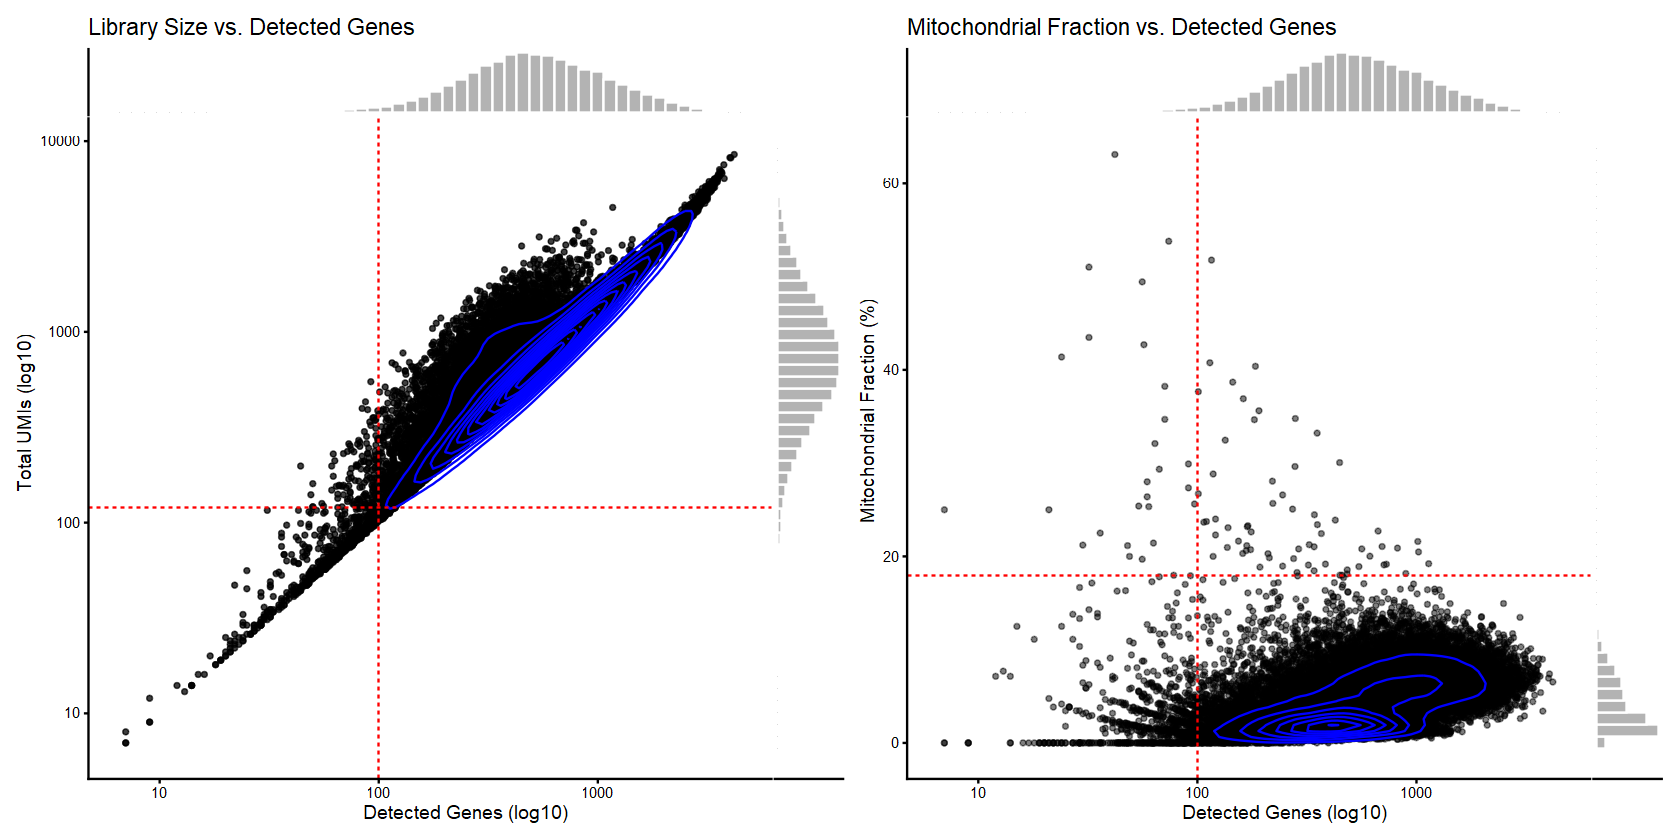

In [27]:
# Display side-by-side
p_scatter1 + p_scatter2

In the left panel, the red dashed crosshair sits precisely at the base of the lowest 2D density contour. Rather than truncating viable, low-yield stromal and immune populations (as the naive 300 UMI / 200 gene cutoffs did), this relaxed floor cleanly isolates the sparse trailing debris tail (the bottom ≈2.2% of cells). 

In the right panel, the 18% threshold aligns with the natural shoulder of the marginal histogram. This safely preserves metabolically active crypt epithelium (10%–18% mitochondrial reads) while strictly filtering damaged cells that display catastrophic membrane rupture and severe transcript dropout (<100 genes, >18% MT).

In [28]:
# Define relaxed global baseline thresholds (technical floor)
sfe$qc_lib_size  <- sfe$sum < min_sum
sfe$qc_detected  <- sfe$detected < min_detected
sfe$qc_mito_prop <- sfe$subsets_Mito_percent > max_mito

# Combine global flags
sfe$global_outliers <- sfe$qc_lib_size | sfe$qc_detected | sfe$qc_mito_prop

# Combine global and local outliers into our final discard flag
sfe$discard <- sfe$global_outliers | sfe$local_outliers

In [29]:
# Cross-tabulate global vs. local outlier flags
table(Global = sfe$global_outliers, Local = sfe$local_outliers)

       Local
Global  FALSE  TRUE
  FALSE 33709   190
  TRUE    867   108

In [30]:
# Tabulate final combined discard numbers
table(Discard = sfe$discard)

Discard
FALSE  TRUE 
33709  1165 

By calibrating these thresholds directly to the empirical data contours (with mitochondrial content capped at 18%), global exclusions drop from nearly 14% (>4,700 cells) down to 2.80% (975 cells), comprising 867 global-only outliers and 108 cells also flagged locally. Combined with `SpotSweeper` local outliers (298 cells, 108 of which overlap), the final filtering gate discards only **1,165 cells (3.34%)**, safeguarding biological tissue compartments while maintaining an essential technical safety net that preserves 33,709 viable cells (96.66%).

### Spatial validation of the final exclusion gate

In [31]:
# Panel 1: Relaxed global floor outliers
p_global <- plotSpatialFeature(sfe, colGeometryName = "cellSeg", features = "global_outliers") +
  scale_fill_manual(values = c("FALSE" = "gray90", "TRUE" = "darkorange2"), name = "Global Floor") +
  labs(title = "Relaxed Global Outliers")

# Panel 2: SpotSweeper local outliers
p_local <- plotSpatialFeature(sfe, colGeometryName = "cellSeg", features = "local_outliers") +
  scale_fill_manual(values = c("FALSE" = "gray90", "TRUE" = "firebrick"), name = "Local Outlier") +
  labs(title = "SpotSweeper Local Outliers")

# Panel 3: Final combined discard flag
p_discard <- plotSpatialFeature(sfe, colGeometryName = "cellSeg", features = "discard") +
  scale_fill_manual(values = c("FALSE" = "gray90", "TRUE" = "purple4"), name = "Discard Flag") +
  labs(title = "Final Combined Discard")

Scale for fill is already present.
Adding another scale for fill, which will replace the existing scale.
Scale for fill is already present.
Adding another scale for fill, which will replace the existing scale.
Scale for fill is already present.
Adding another scale for fill, which will replace the existing scale.


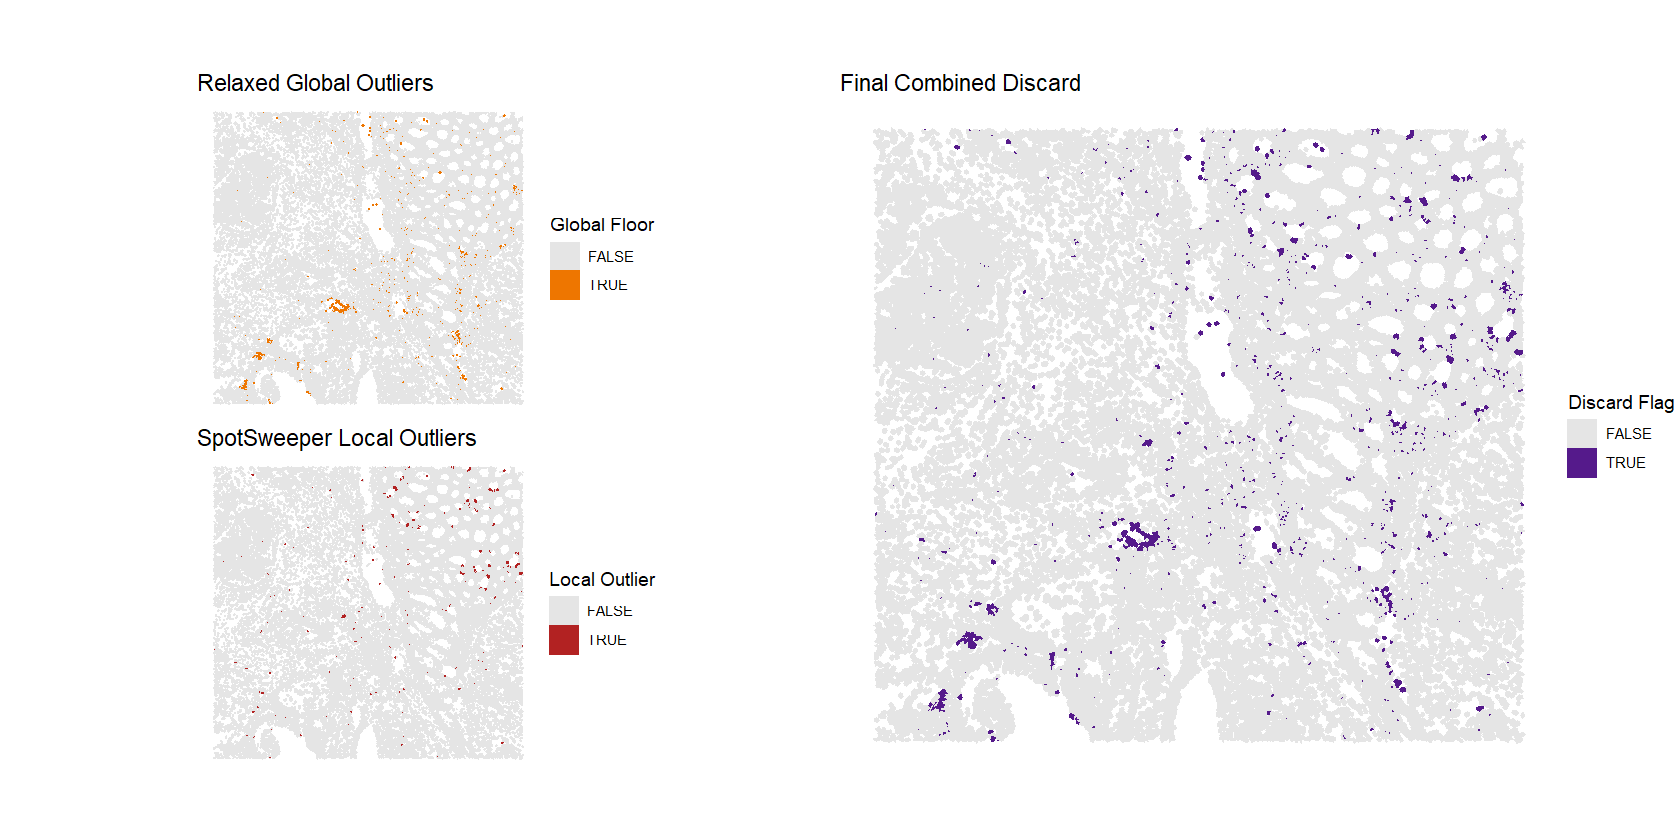

In [32]:
# Display 3-panel spatial synthesis
(p_global / p_local) | p_discard

The organized mucosal crypts in the upper right remain almost entirely intact (light gray). Despite their elevated baseline respiration (10%–18% mitochondrial reads), their epithelial rings are successfully spared from false-positive exclusion, as are the low-yield desmoplastic stroma and tumor parenchyma. 

Importantly, the discarded cells (purple) strictly concentrate in the genuine defect zones identified throughout our spatial diagnosis:

- The physically sheared tissue margins and mechanical cutting tears along the lower boundary.
- Debris lining the borders of the central submucosal vascular lumens.
- Isolated, focal dropouts scattered across the tissue.

By pairing a relaxed global floor with localized neighborhood testing, we eliminate true technical artifacts without disrupting valid histology!

### Region-level technical artifacts

Mechanical cryosectioning can cause macroscopic tissue folding, stretching, or detachment ("hangnail" artifacts) where entire regions lose transcript integrity. To address this, `SpotSweeper` provides `findArtifacts()`, an algorithm designed to identify multi-spot regional defects by evaluating the multi-scale spatial variance of mitochondrial expression across neighboring orders ($k$-rings from order 1 to 5).

In [33]:
# Detect region-level artifacts using SpotSweeper
sfe <- tryCatch(
  findArtifacts(sfe,
    mito_percent = "subsets_Mito_percent",
    mito_sum     = "subsets_Mito_sum",
    n_order      = 5,
    name         = "artifact"
  ),
  error = function(e) {
    message("findArtifacts() could not fit an artifact model: ", conditionMessage(e))
    sfe$artifact <- FALSE
    sfe
  }
)

Warning message in BiocParallel::MulticoreParam(workers):
"MulticoreParam() not supported on Windows, use SnowParam()"
Warning message in BiocParallel::MulticoreParam(workers):
"MulticoreParam() not supported on Windows, use SnowParam()"
Warning message in BiocParallel::MulticoreParam(workers):
"MulticoreParam() not supported on Windows, use SnowParam()"
Warning message in BiocParallel::MulticoreParam(workers):
"MulticoreParam() not supported on Windows, use SnowParam()"
Warning message in BiocParallel::MulticoreParam(workers):
"MulticoreParam() not supported on Windows, use SnowParam()"


In [34]:
# Tabulate the resulting artifact classification
table(Artifact = sfe$artifact)

Artifact
FALSE  TRUE 
14313 20561 

The tabulation reveals an alarming result: `findArtifacts()` flags **20,561 cells (58.96%)** as technical artifacts, leaving only 14,313 cells (41.04%) designated as intact.

This massive split directly reflects the algorithm's hardcoded $k=2$ clustering mechanism, which is mathematically forced to bifurcate the entire slide into two macro-cohorts regardless of actual tissue quality. As [explained by the authors](https://pmc.ncbi.nlm.nih.gov/articles/PMC12258134/), the method was tailored for brain slices to detect specific macroscopic flaws: *"SpotSweeper is able to accurately identify two distinct classes of regional artifacts, namely dryspots and hangnails, caused by incomplete coverage of permeabilization agents and tissue damage, respectively."*

Clearly, discarding nearly 60% of our sequencing library is biologically untenable and indicates that `findArtifacts()` is ill-suited for complex, heterogeneous tumor microenvironments. Purely out of curiosity and for pedagogical demonstration, we can map this `artifact` flag across the tissue to visualize what the algorithm actually captured and confirm why it must be excluded from our filtering workflow.

Scale for fill is already present.
Adding another scale for fill, which will replace the existing scale.


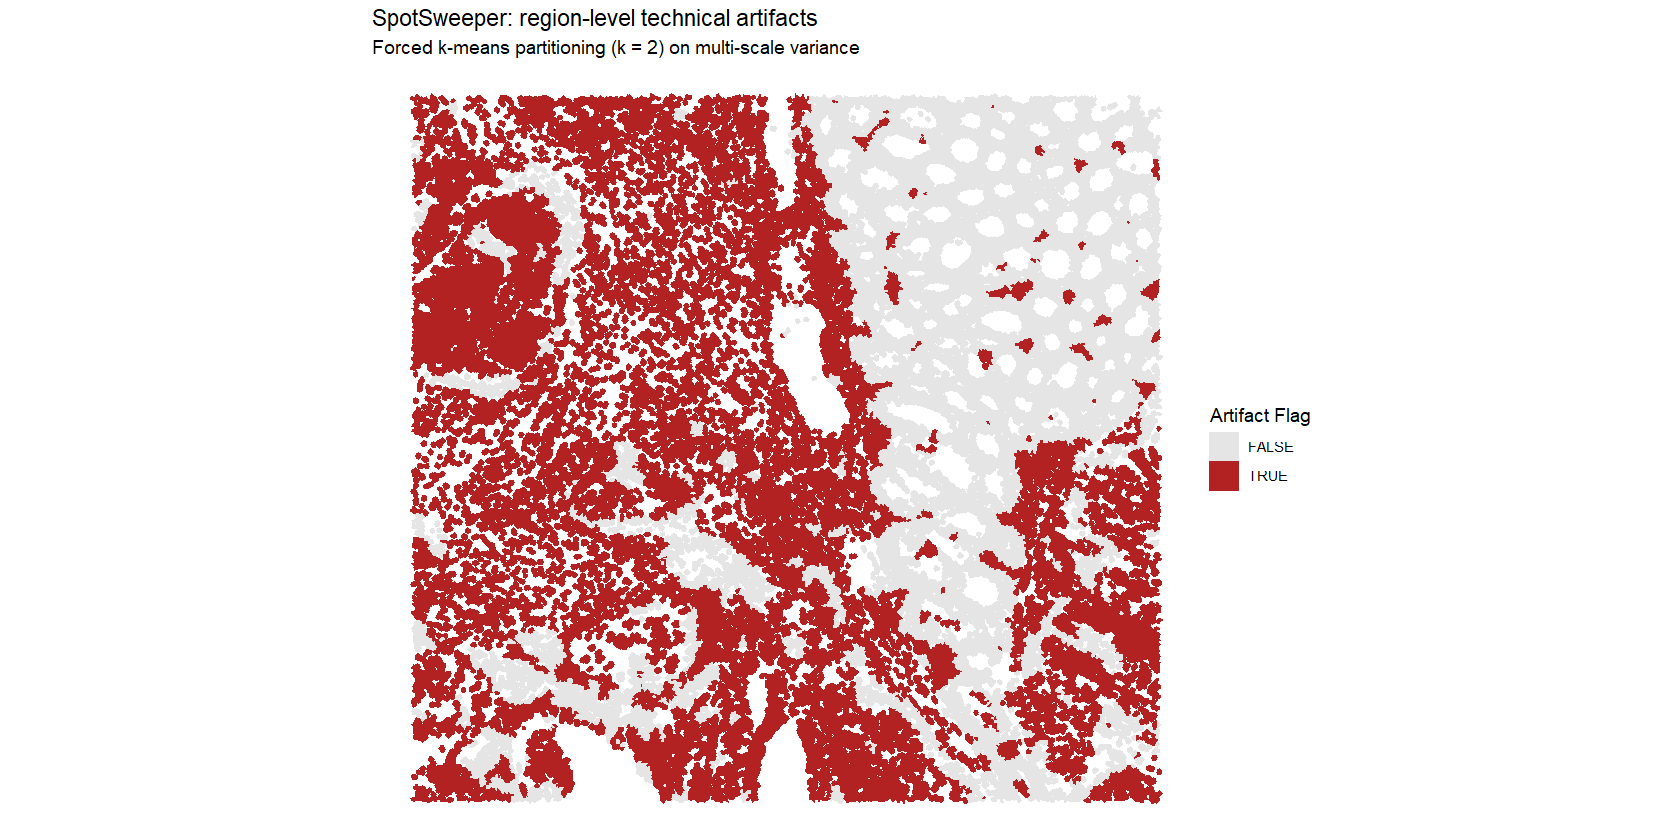

In [35]:
# Map the detected regional artifact across segmented cell polygons
plotSpatialFeature(sfe, colGeometryName = "cellSeg", features = "artifact") +
  scale_fill_manual(values = c("FALSE" = "gray90", "TRUE" = "firebrick"), name = "Artifact Flag") +
  labs(
    title = "SpotSweeper: region-level technical artifacts",
    subtitle = "Forced k-means partitioning (k = 2) on multi-scale variance"
  )

The algorithm flagged the **entire invasive adenocarcinoma and stroma on the left** simply because this continuous tumor bed has lower local variance in mitochondrial content than the crypt-rich normal mucosa on the right. 

Rather than identifying a mechanical tear, the method has mapped an authentic histopathological boundary. Blindly applying this filter would eliminate the primary tumor compartment under study. 

We therefore **reject** the `artifact` column and rely strictly on our validated two-tiered `discard` flag (`global_outliers | local_outliers`).

## Finalizing the object

### Filtering low-quality cells and unexpressed genes

Quality control filtering must be executed in two sequential stages across the **two dimensions** of our dataset: first on observations (_cells_), and then on features (_genes_).

1. **Step 1: Cell-level filtering (`!sfe$discard`).** We subset the columns of our object to retain only the cells that passed both our empirical global boundaries and local neighborhood outlier tests.
2. **Step 2: Gene-level filtering (`rowSums(counts(sfe)) > 0`).** With non-viable cells removed, we prune inactive genes that have zero detected counts across all remaining cells.

In [36]:
# Step 1: Filter low-quality cells (and synchronize all spatial geometries)
sfe <- sfe[, !sfe$discard]

# Step 2: Prune unexpressed genes across the remaining viable cell cohort
sfe <- sfe[rowSums(counts(sfe)) > 0, ]

# Inspect the final dimensions of the filtered object
sfe

class: SpatialFeatureExperiment 
dim: 18049 33709 
metadata(1): Samples
assays(1): counts
rownames(18049): SAMD11 NOC2L ... MT-ND6 MT-CYB
rowData names(4): ID Symbol Type subsets_Mito
colnames(33709): 80404 80411 ... 189331 189341
colData names(33): Sample Barcode ... k90 artifact
reducedDimNames(1): PCA_artifacts
mainExpName: NULL
altExpNames(0):
spatialCoords names(2) : pxl_col_in_fullres pxl_row_in_fullres
imgData names(4): sample_id image_id data scaleFactor

unit: micron
Geometries:
colGeometries: centroids (POINT), cellSeg (POLYGON), nucSeg (POLYGON) 

Graphs:
sample01: 

Subsetting our object yields a high-confidence, single-cell spatial dataset:

- **Retained cells:** **33,709 cells** (reduced from 34,874; **96.66%** retained, discarding 1,165 low-quality events or 3.34%).
- **Retained genes:** **18,049 genes** (reduced from 18,132; pruning **83 unexpressed genes** that had zero counts across the remaining cells).  This is a critical standalone QC step: removing these zero-variance features prevents numerical failures during normalization and PCA, avoids inflating multiple-testing FDR penalties, and reduces memory and storage footprints.
- **Synchronized geometries:** All spatial metadata layers, including `cellSeg` and `nucSeg` polygons, centroid coordinates, and spatial neighbor graphs, have been automatically subset in exact alignment with the retained cell cohort.

### Saving the filtered dataset

As established in our previous ingestion workflows, standard serialization functions (such as `.rds` or standard HDF5 savers) cannot reliably serialize the complex multi-layer `sf` spatial geometries (`cellSeg`, `nucSeg`) embedded within a `SpatialFeatureExperiment` object.

To preserve the complete object architecture, we use the `alabaster.sfe` framework. This serializes our filtered count matrix, cell metadata, spatial coordinates, and vector polygon geometries into a modular, language-agnostic directory on disk. 

We save the object to `output/sfe_visiumhd_segmented_qc-filtered`, which serves as the primary input for downstream normalization and scaling in the upcoming notebooks.

In [37]:
# Define the standardized output directory path for downstream Day 2 analysis
out_path <- "output/sfe_visiumhd_segmented_qc-filtered"

# Ensure the target parent directory exists
dir.create(dirname(out_path), recursive = TRUE, showWarnings = FALSE)

# Remove any existing directory to prevent overwriting errors
if (dir.exists(out_path)) {
  unlink(out_path, recursive = TRUE)
}

# Save the filtered SFE object and all associated spatial geometries to disk
alabaster.sfe::saveObject(sfe, out_path)

>>> Saving SpatialExperiment

>>> Saving colgeometries



In [38]:
# Inspect the modular directory structure created by alabaster.sfe
fs::dir_tree(out_path)

output/sfe_visiumhd_segmented_qc-filtered
├── assays
│   ├── 0
│   │   ├── matrix.h5
│   │   └── OBJECT
│   └── names.json
├── colgeometries
│   ├── 0
│   │   ├── map.parquet
│   │   └── OBJECT
│   ├── 1
│   │   ├── map.parquet
│   │   └── OBJECT
│   ├── 2
│   │   ├── map.parquet
│   │   └── OBJECT
│   └── names.json
├── column_data
│   ├── basic_columns.h5
│   ├── OBJECT
│   └── other_columns
│       └── 26
│           ├── array.h5
│           └── OBJECT
├── coordinates
│   ├── array.h5
│   └── OBJECT
├── images
│   ├── 0
│   │   ├── image.tiff
│   │   └── OBJECT
│   ├── 1
│   │   ├── image.tiff
│   │   └── OBJECT
│   └── mapping.h5
├── OBJECT
├── other_data
│   ├── list_contents.json.gz
│   └── OBJECT
├── reduced_dimensions
│   ├── 0
│   │   ├── array.h5
│   │   ├── attrs
│   │   │   ├── list_contents.json.gz
│   │   │   └── OBJECT
│   │   └── OBJECT
│   └── names.json
├── row_data
│   ├── basic_columns.h5
│   └── OBJECT
└── _environment.json


### Clearing the workspace

Because high-resolution spatial transcriptomic datasets and their associated cell-segmentation polygons occupy substantial memory (several gigabytes of RAM), it is best practice to clear the active workspace before proceeding. This ensures all allocated memory is returned to the system and prevents variable leakage into subsequent notebooks.

*(Note: In interactive IDEs such as RStudio or Positron, restarting the active R session via the menu bar is also recommended before opening the next notebook).*

In [39]:
# Clear all variables from the R environment
rm(list = ls())

# Aggressively trigger garbage collection to reclaim system RAM
gc()

,used,(Mb),gc trigger,(Mb),max used,(Mb)
Ncells,13510769,721.6,21396897,1142.8,21396897,1142.8
Vcells,27213274,207.7,70203621,535.7,70203621,535.7
